# SimulaHub · Módulo 1 – CFD e Modelagem Hemodinâmica
## Dia 5 (07/11) – Do CFD aos dados e à Inteligência Artificial
**Atividade prática da tarde** · Docente: Profª. Drª. Rita de Cássia dos Anjos (UFSCar) · Tutor: Willian Costa de Paula (UTFPR)

---

**Pergunta-guia:** *como a geometria de um vaso influencia o fluxo sanguíneo?*

Neste notebook, cada **simulação** é tratada como um **experimento que gera dados**. O arquivo `simulacoes_0d.csv` tem **600 simulações 0D** da bifurcação aorta → ilíacas (o mesmo modelo do notebook do Dia 3), em que sorteamos cinco entradas e registramos as saídas. Vamos:

1. ler e organizar os dados com **pandas**;
2. explorar os dados com gráficos (**análise exploratória**);
3. separar **treino** e **teste**;
4. treinar modelos de **regressão** (linear e Random Forest) com o **scikit-learn** para prever a queda de pressão $\Delta P$;
5. comparar **CFD × ML** e ver quais variáveis mais pesam;
6. **classificar** lesões significativas ($P_d/P_a < 0{,}80$) com regressão logística;
7. discutir as **limitações**: o modelo aprende com as simulações e não substitui a física.

Ao final há **4 exercícios para entregar**.

### Como usar
- Faça o upload deste notebook **e** do arquivo `simulacoes_0d.csv` (a primeira célula pede o arquivo se ele não estiver no Colab).
- Execute as células em ordem com `Shift + Enter`. Cada linha de código tem um comentário explicando o que faz.
- Se algo der errado: **Ambiente de execução → Reiniciar e executar tudo**.

## 1. Lendo os dados com pandas

In [1]:
import os                                           # para verificar se o arquivo existe
import numpy as np                                  # cálculos numéricos
import pandas as pd                                 # tabelas de dados (DataFrames)
import matplotlib.pyplot as plt                     # gráficos
plt.rcParams["figure.figsize"] = (8, 5)             # tamanho padrão das figuras
plt.rcParams["font.size"] = 12                      # tamanho padrão das fontes

if not os.path.exists("simulacoes_0d.csv"):         # se o arquivo ainda não está no Colab...
    from google.colab import files                  # ...ferramenta de upload do Colab
    files.upload()                                  # escolha simulacoes_0d.csv

dados = pd.read_csv("simulacoes_0d.csv")            # lê a tabela: uma linha por simulação
print(f"{dados.shape[0]} simulações (linhas) e {dados.shape[1]} colunas")
dados.head()                                        # mostra as 5 primeiras linhas

600 simulações (linhas) e 11 colunas


,reducao_area,vazao_media,raio_iliaca,rigidez_EH,R_saida,deltaP_mmHg,Pd_Pa,Q_esq,P_sist_aorta,P_diast_aorta,significativa
0,0.7789,37.43,0.4551,335100.0,8302.0,10.761,0.9215,20.264,183.092,100.413,0
1,0.8905,15.13,0.4642,678200.0,10147.0,7.212,0.8848,7.277,90.158,41.728,0
2,0.5831,21.96,0.3510,467000.0,10550.0,1.962,0.9778,10.898,116.305,63.512,0
3,0.7419,39.89,0.4585,573300.0,15879.0,5.105,0.9735,15.737,253.982,139.049,0
4,0.5086,19.01,0.4225,226400.0,5392.0,0.722,0.9860,12.555,65.198,39.063,0


**O que significa cada coluna:**

| coluna | papel | significado | unidade |
|---|---|---|---|
| `reducao_area` | entrada (*feature*) | fração da área da ilíaca esquerda obstruída pela estenose | 0 a 1 |
| `vazao_media` | entrada | vazão média que entra na aorta | mL/s |
| `raio_iliaca` | entrada | raio da ilíaca esquerda | cm |
| `rigidez_EH` | entrada | rigidez × espessura da parede ($E\cdot h$) | dyn/cm |
| `R_saida` | entrada | resistência dos vasos a jusante da ilíaca esquerda | dyn·s/cm⁵ |
| `deltaP_mmHg` | saída (*target*) | queda de pressão média na ilíaca esquerda | mmHg |
| `Pd_Pa` | saída | pressão depois ÷ pressão antes da estenose (como o FFR) | – |
| `Q_esq` | saída | vazão média na ilíaca esquerda | mL/s |
| `P_sist_aorta`, `P_diast_aorta` | saídas | pressões máxima e mínima na aorta | mmHg |
| `significativa` | saída | 1 se $P_d/P_a < 0{,}80$ (lesão significativa), 0 caso contrário | – |

Cada linha é um experimento: escolhemos as entradas, rodamos a simulação e anotamos as saídas.

In [2]:
print(dados.describe().round(2).T)                   # estatísticas de cada coluna: média, mínimo, máximo…
print("\nValores ausentes por coluna:", dados.isna().sum().sum())   # verificar se há buracos na tabela
print(f"Lesões significativas: {dados['significativa'].sum()} de {len(dados)} ({dados['significativa'].mean()*100:.0f}%)")

               count       mean        std        min        25%        50%  \
reducao_area   600.0       0.66       0.20       0.11       0.53       0.69   
vazao_media    600.0      27.29       7.19      15.13      21.17      26.73   
raio_iliaca    600.0       0.40       0.06       0.30       0.35       0.41   
rigidez_EH     600.0  514265.50  171685.19  202000.00  368175.00  513400.00   
R_saida        600.0   10502.96    3227.39    5023.00    7670.75   10407.00   
deltaP_mmHg    600.0      11.22      17.80       0.07       1.18       4.07   
Pd_Pa          600.0       0.91       0.12       0.27       0.87       0.96   
Q_esq          600.0      13.30       4.01       5.99      10.05      13.16   
P_sist_aorta   600.0     150.38      47.99      59.69     110.63     144.66   
P_diast_aorta  600.0      79.17      26.85      28.47      57.40      74.44   
significativa  600.0       0.15       0.36       0.00       0.00       0.00   

                     75%        max  
reducao_area 

---
## 2. Análise exploratória: olhar antes de modelar

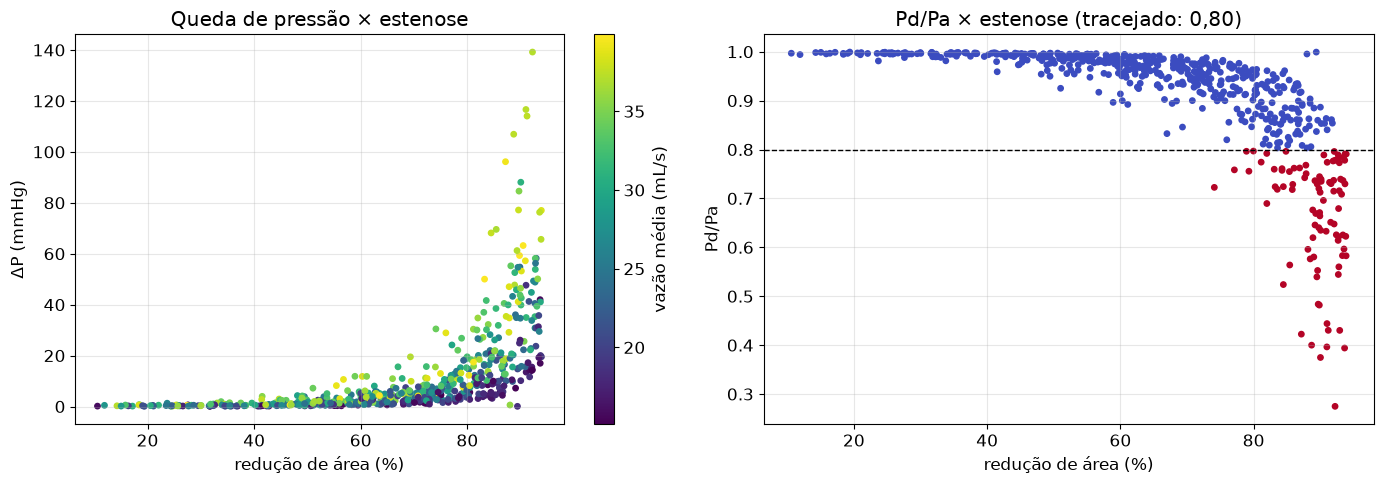

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sc = ax[0].scatter(dados["reducao_area"]*100, dados["deltaP_mmHg"], c=dados["vazao_media"], cmap="viridis", s=15)  # cada ponto é uma simulação
plt.colorbar(sc, ax=ax[0], label="vazão média (mL/s)")
ax[0].set(xlabel="redução de área (%)", ylabel="ΔP (mmHg)", title="Queda de pressão × estenose")
ax[1].scatter(dados["reducao_area"]*100, dados["Pd_Pa"], c=dados["significativa"], cmap="coolwarm", s=15)          # vermelho = significativa
ax[1].axhline(0.80, ls="--", c="k", lw=1)                                                                           # limiar clínico
ax[1].set(xlabel="redução de área (%)", ylabel="Pd/Pa", title="Pd/Pa × estenose (tracejado: 0,80)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Interpretação:** até cerca de 60% de redução de área, a queda de pressão é praticamente nula. Acima de ~80%, ela dispara: é a **estenose crítica**. Com mais vazão (pontos amarelos), a queda é maior, porque a perda na estenose cresce com $Q^2$ (Young e Tsai, Dia 3). Um modelo de ML precisa conseguir representar essa curva.

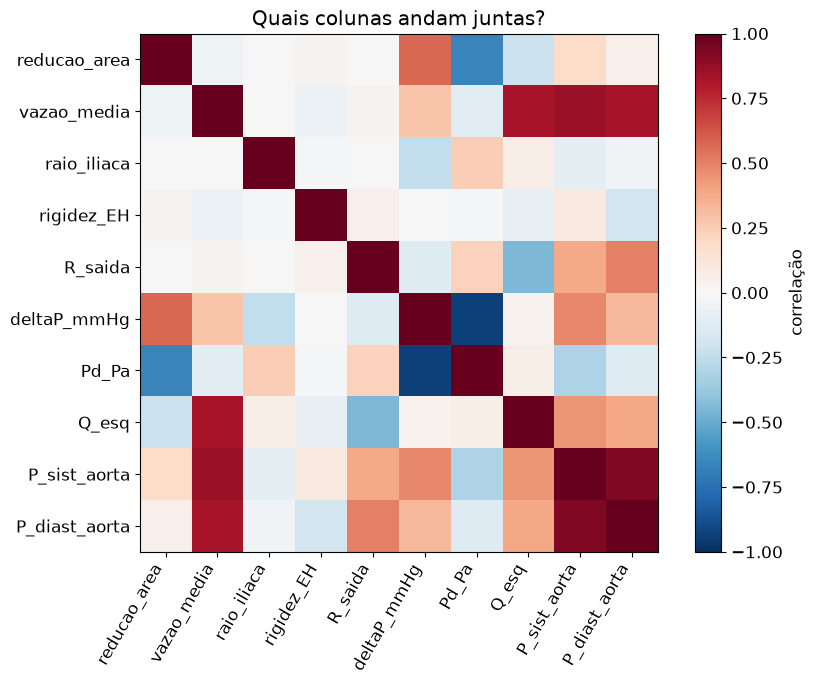

In [4]:
correl = dados.drop(columns="significativa").corr()             # correlação entre todas as colunas (−1 a 1)
plt.figure(figsize=(9, 7))
plt.imshow(correl, cmap="RdBu_r", vmin=-1, vmax=1)               # mapa de cores da matriz de correlação
plt.xticks(range(len(correl)), correl.columns, rotation=60, ha="right"); plt.yticks(range(len(correl)), correl.columns)
plt.colorbar(label="correlação"); plt.title("Quais colunas andam juntas?"); plt.tight_layout(); plt.show()

A **correlação** mede quanto duas variáveis crescem (ou diminuem) juntas em linha reta. Ela capta só relações lineares: a relação entre estenose e $\Delta P$ é forte, mas curva, e a correlação a subestima.

---
## 3. Treino e teste

In [5]:
from sklearn.model_selection import train_test_split               # função que divide os dados

FEATURES = ["reducao_area", "vazao_media", "raio_iliaca", "rigidez_EH", "R_saida"]   # as entradas
X = dados[FEATURES]                                                 # tabela de entradas
y = dados["deltaP_mmHg"]                                            # o que queremos prever

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)    # 80% treino, 20% teste
print(f"treino: {len(X_tr)} simulações ; teste: {len(X_te)} simulações")

treino: 480 simulações ; teste: 120 simulações


O conjunto de **teste** fica guardado: o modelo nunca o vê durante o treino. É a “prova” que mede se ele **generaliza** para casos novos. `random_state=42` fixa o sorteio, para que todos obtenham o mesmo resultado.

---
## 4. Regressão: prevendo a queda de pressão

In [6]:
from sklearn.pipeline import Pipeline                              # encadeia etapas em um só objeto
from sklearn.preprocessing import StandardScaler                   # padroniza (média 0, desvio 1)
from sklearn.linear_model import LinearRegression                  # regressão linear
from sklearn.ensemble import RandomForestRegressor                 # floresta aleatória
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear = Pipeline([("padroniza", StandardScaler()), ("modelo", LinearRegression())])   # padronizar e depois ajustar a reta
floresta = RandomForestRegressor(n_estimators=300, random_state=42)                    # 300 árvores de decisão

linear.fit(X_tr, y_tr)                                              # aprender com o treino
floresta.fit(X_tr, y_tr)

def avaliar(modelo, X_, y_):
    # devolve MAE, RMSE e R² de um modelo em um conjunto de dados
    p = modelo.predict(X_)
    return mean_absolute_error(y_, p), mean_squared_error(y_, p)**0.5, r2_score(y_, p)

for nome, m in [("Regressão linear", linear), ("Random Forest", floresta)]:
    mae, rmse, r2 = avaliar(m, X_te, y_te)
    print(f"{nome:17s}: MAE = {mae:5.2f} mmHg ; RMSE = {rmse:5.2f} mmHg ; R² = {r2:.3f}")

Regressão linear : MAE =  7.62 mmHg ; RMSE = 10.55 mmHg ; R² = 0.542
Random Forest    : MAE =  2.81 mmHg ; RMSE =  6.21 mmHg ; R² = 0.841


**As métricas:**
- **MAE** (erro absoluto médio): quanto o modelo erra, em média, em mmHg.
- **RMSE** (raiz do erro quadrático médio): parecido, mas pune mais os erros grandes.
- **R²**: fração da variação dos dados que o modelo explica (1 = perfeito, 0 = tão bom quanto chutar a média).

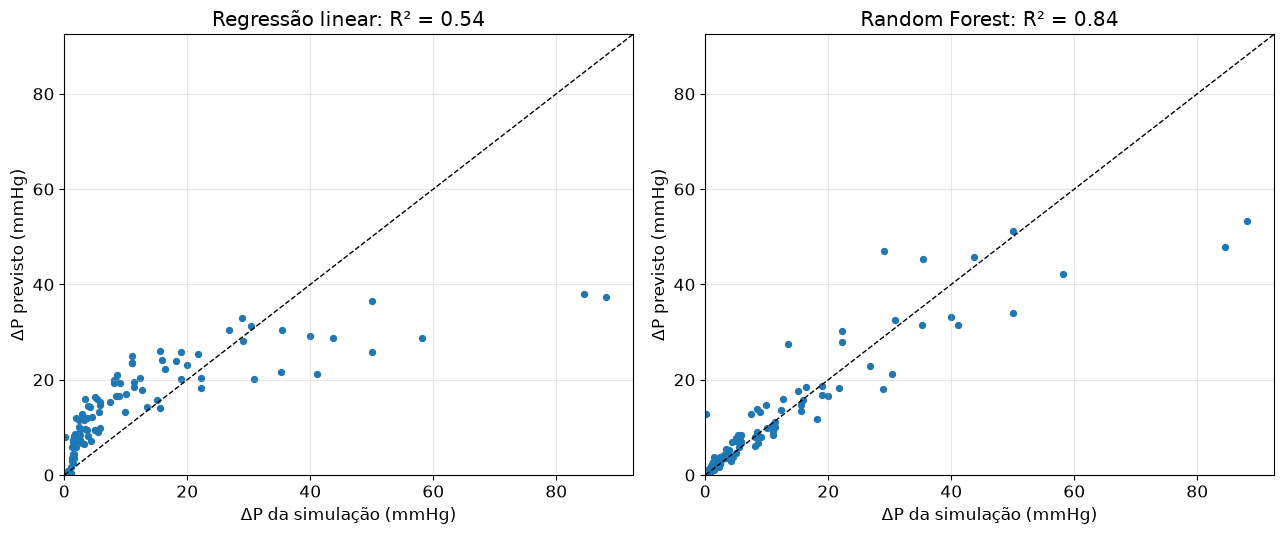

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (nome, m) in zip(ax, [("Regressão linear", linear), ("Random Forest", floresta)]):
    p = m.predict(X_te)                                              # previsões para o teste
    a.scatter(y_te, p, s=18)                                         # previsto × simulado
    lim = [0, max(y_te.max(), p.max())*1.05]; a.plot(lim, lim, "k--", lw=1)   # diagonal = previsão perfeita
    a.set(xlim=lim, ylim=lim, xlabel="ΔP da simulação (mmHg)", ylabel="ΔP previsto (mmHg)", title=f"{nome}: R² = {r2_score(y_te, p):.2f}")
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Interpretação (CFD × ML):** a regressão linear tenta ajustar um plano a uma relação curva e erra muito nas estenoses graves. A Random Forest acompanha a estenose crítica. A escolha do algoritmo precisa respeitar a física do problema.

---
## 5. Quais variáveis mais pesam?

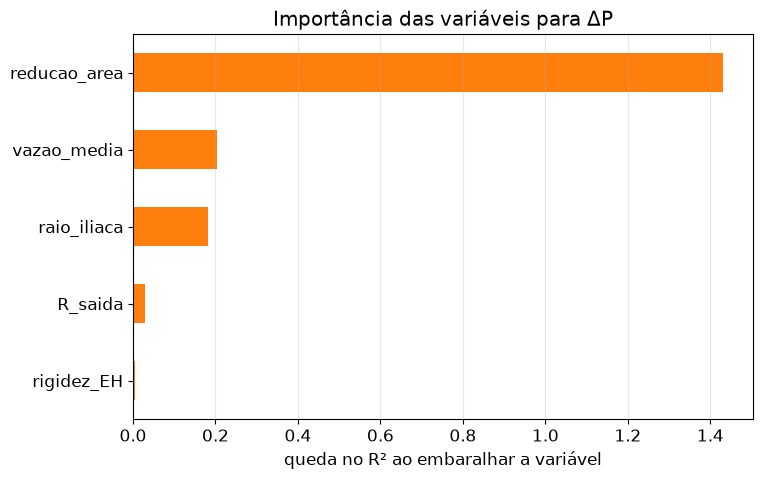

rigidez_EH      0.006
R_saida         0.028
raio_iliaca     0.181
vazao_media     0.203
reducao_area    1.432
dtype: float64


In [8]:
from sklearn.inspection import permutation_importance              # importância por permutação

imp = permutation_importance(floresta, X_te, y_te, n_repeats=20, random_state=0)   # embaralha cada coluna e mede a piora
importancia = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
importancia.plot(kind="barh", color="tab:orange")
plt.xlabel("queda no R² ao embaralhar a variável"); plt.title("Importância das variáveis para ΔP"); plt.grid(axis="x", alpha=.3); plt.show()
print(importancia.round(3))

**Interpretação:** a redução de área domina; a vazão e o raio vêm depois; a rigidez quase não influencia a queda de pressão **média** (no 0D, ela muda a pulsação). Sempre confira se o que o modelo aprendeu faz sentido físico.

---
## 6. Overfitting: decorar não é aprender

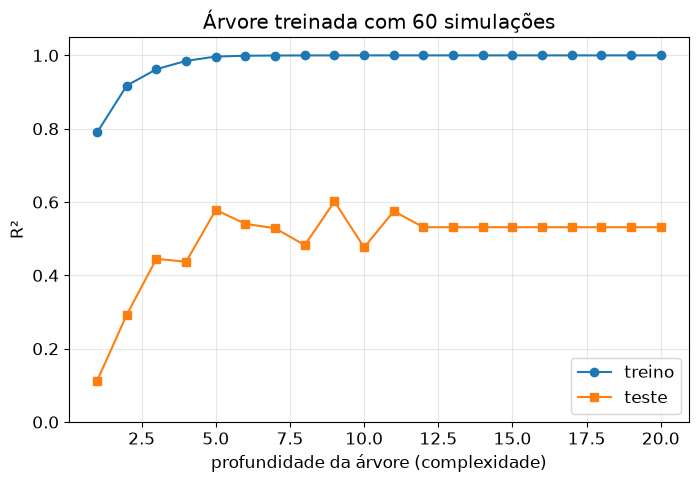

In [9]:
from sklearn.tree import DecisionTreeRegressor                     # uma única árvore de decisão

X_pouco, _, y_pouco, _ = train_test_split(X_tr, y_tr, train_size=60, random_state=1)   # só 60 simulações para treinar
prof = range(1, 21)                                                 # profundidades (complexidade) da árvore
r2_treino, r2_teste = [], []
for d in prof:
    arv = DecisionTreeRegressor(max_depth=d, random_state=0).fit(X_pouco, y_pouco)
    r2_treino.append(r2_score(y_pouco, arv.predict(X_pouco)))     # acerto nos dados que ela viu
    r2_teste.append(r2_score(y_te, arv.predict(X_te)))            # acerto em dados novos
plt.plot(prof, r2_treino, "o-", label="treino"); plt.plot(prof, r2_teste, "s-", label="teste")
plt.xlabel("profundidade da árvore (complexidade)"); plt.ylabel("R²"); plt.ylim(0, 1.05)
plt.title("Árvore treinada com 60 simulações"); plt.legend(); plt.grid(alpha=.3); plt.show()

Com árvores profundas, o R² de treino chega a 1 (acerto perfeito), mas o de teste fica muito menor: o modelo **decorou** os exemplos (sobreajuste, *overfitting*). A Random Forest reduz esse problema fazendo a média de muitas árvores.

---
## 7. Classificação: a lesão é significativa?

Matriz de confusão (linhas = real, colunas = previsto):
[[126   1]
 [  2  21]]
                   precision    recall  f1-score   support

não significativa       0.98      0.99      0.99       127
    significativa       0.95      0.91      0.93        23

         accuracy                           0.98       150
        macro avg       0.97      0.95      0.96       150
     weighted avg       0.98      0.98      0.98       150

AUC = 0.996


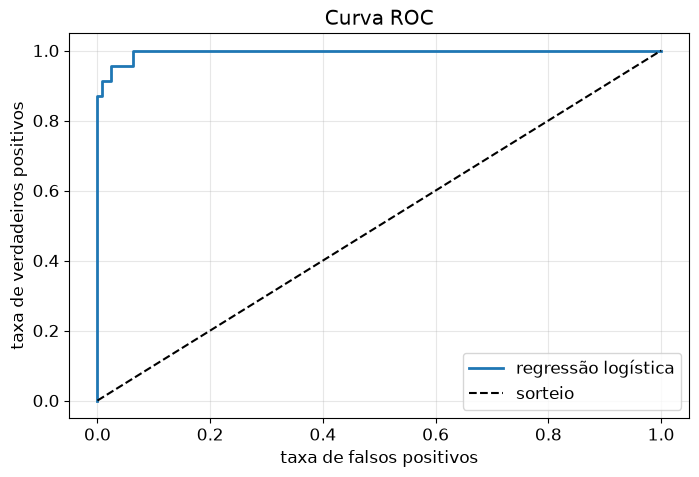

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

yc = dados["significativa"]                                          # alvo: 1 = Pd/Pa < 0,80
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X, yc, test_size=0.25, random_state=42, stratify=yc)  # stratify: mesma proporção nos dois

logistica = Pipeline([("padroniza", StandardScaler()), ("modelo", LogisticRegression(max_iter=2000))])
logistica.fit(Xc_tr, yc_tr)                                          # aprender
prob = logistica.predict_proba(Xc_te)[:, 1]                         # probabilidade de ser significativa
prev = (prob >= 0.5).astype(int)                                    # decisão com limiar 0,5

print("Matriz de confusão (linhas = real, colunas = previsto):")
print(confusion_matrix(yc_te, prev))
print(classification_report(yc_te, prev, target_names=["não significativa", "significativa"]))
print(f"AUC = {roc_auc_score(yc_te, prob):.3f}")

fpr, tpr, _ = roc_curve(yc_te, prob)
plt.plot(fpr, tpr, lw=2, label="regressão logística"); plt.plot([0, 1], [0, 1], "k--", label="sorteio")
plt.xlabel("taxa de falsos positivos"); plt.ylabel("taxa de verdadeiros positivos"); plt.title("Curva ROC"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Como ler:**
- **Matriz de confusão:** na diagonal, os acertos; fora dela, os erros. O canto inferior esquerdo são os **falsos negativos**: lesões graves que o modelo deixou passar, o pior erro em saúde.
- **Precisão:** dos casos que o modelo chamou de significativos, quantos eram. **Revocação** (*recall*): dos significativos, quantos ele encontrou.
- **Curva ROC e AUC:** desempenho para todos os limiares de decisão; AUC = 0,5 é um sorteio, 1 é perfeito.

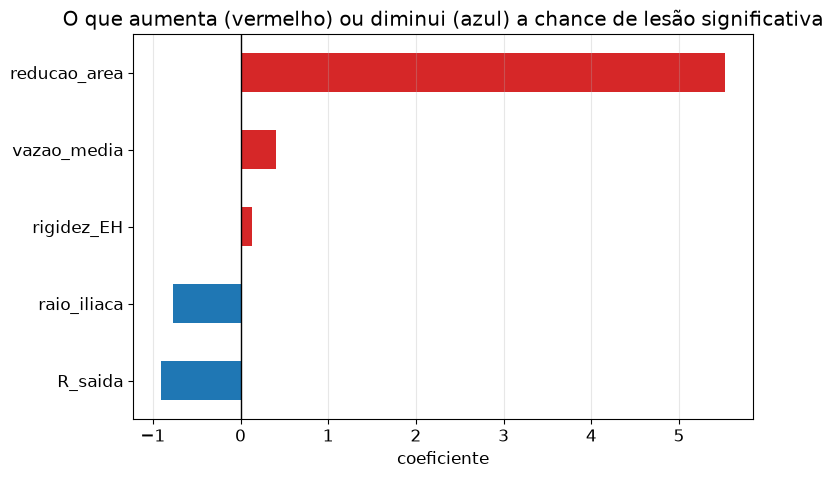

In [11]:
coef = pd.Series(logistica.named_steps["modelo"].coef_[0], index=FEATURES).sort_values()   # pesos das variáveis padronizadas
coef.plot(kind="barh", color=["tab:blue" if v < 0 else "tab:red" for v in coef]); plt.axvline(0, c="k", lw=1)
plt.xlabel("coeficiente"); plt.title("O que aumenta (vermelho) ou diminui (azul) a chance de lesão significativa"); plt.grid(axis="x", alpha=.3); plt.show()

**Interpretação:** mais estenose e mais vazão aumentam a chance; um vaso maior e mais resistência a jusante diminuem (passa menos sangue pela lesão). Tudo coerente com os Dias 1 a 3.

---
## 8. Surrogate model: prever sem simular

In [12]:
import time
caso = pd.DataFrame([[0.85, 30.0, 0.40, 4e5, 10600]], columns=FEATURES)   # uma estenose nova: 85% de área, 30 mL/s…
print(f"ΔP previsto pela Random Forest: {floresta.predict(caso)[0]:.1f} mmHg")

muitos = pd.concat([caso]*10000)                                           # 10 000 cenários
t0 = time.time(); floresta.predict(muitos); dt = time.time() - t0
print(f"10 000 previsões em {dt:.2f} s")

ΔP previsto pela Random Forest: 20.6 mmHg


10 000 previsões em 0.04 s


Um **surrogate model** (modelo substituto) é um modelo de ML treinado com simulações que responde em milissegundos. Aqui o ganho é pequeno, porque o 0D já é rápido; o valor real aparece quando cada simulação 3D leva horas.

**Limites:** o modelo só é confiável **dentro da faixa** em que foi treinado, herda as hipóteses das simulações (0D, parede rígida nas ilíacas, sangue newtoniano) e não tem nenhuma garantia de obedecer à física. Ele **complementa**, não substitui, a modelagem física.

---
## Resumo do dia
| Etapa | Ferramenta | O que vimos |
|---|---|---|
| ler e organizar | `pandas.read_csv`, `describe` | 600 simulações, 5 entradas, várias saídas |
| explorar | gráficos, correlação | estenose crítica a partir de ~80% de área |
| dividir | `train_test_split` | 80% treino, 20% teste |
| regressão | `LinearRegression`, `RandomForestRegressor` | Random Forest acompanha a física (R² ≈ 0,86) |
| importância | `permutation_importance` | redução de área domina |
| overfitting | `DecisionTreeRegressor` | treino perfeito ≠ teste bom |
| classificação | `LogisticRegression` | matriz de confusão, ROC |
| surrogate | `predict` | rápido, mas só dentro da faixa de treino |

**Resultado esperado do dia:** entender como dados produzidos por CFD podem ser usados em modelos simples de aprendizado de máquina e como a IA pode atuar como ferramenta complementar à modelagem física.

---
# Exercícios para entregar

**Instruções**
- Resolva cada exercício nas células indicadas; crie células novas se precisar.
- Gráficos com **eixos rotulados com unidades e título**.
- Respostas conceituais em células de texto.
- Ao terminar: **Ambiente de execução → Reiniciar e executar tudo**.
- Baixe em **Arquivo → Fazer download → Fazer download do .ipynb**, nomeie como `NomeSobrenome_Dia5.ipynb` e envie até **[prazo a definir pela docente]**.

### Exercício 1 – Outro alvo: a pressão sistólica na aorta

a) Treine uma Random Forest para prever `P_sist_aorta` (em vez de `deltaP_mmHg`), com as mesmas entradas e a mesma divisão treino/teste (80/20, `random_state=42`). Calcule MAE e R² no teste.

b) Calcule a importância por permutação das variáveis e faça o gráfico.

c) As variáveis mais importantes mudaram em relação ao $\Delta P$? Explique fisicamente, lembrando do papel da rigidez da parede e da resistência de saída (Dias 3 e 4).

Item (a) – Desempenho do Modelo para Pressão Sistólica na Aorta:
MAE =  6.68 mmHg ; RMSE =  9.49 mmHg ; R² = 0.963


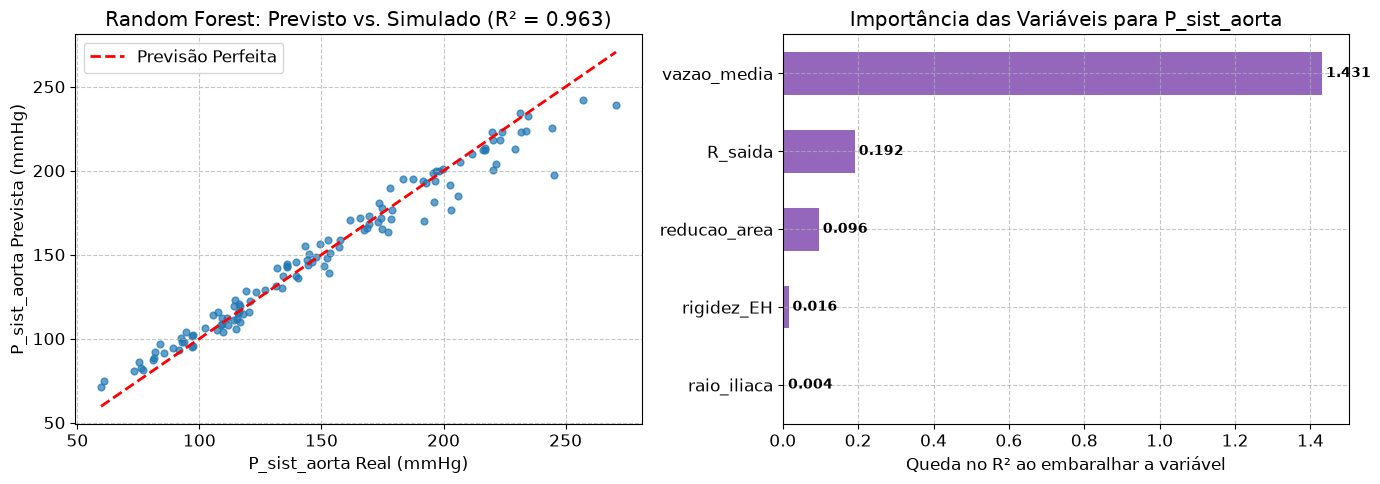

Item (b) – Ranking de Importância por Permutação:
vazao_media    : 1.4312
R_saida        : 0.1917
reducao_area   : 0.0964
rigidez_EH     : 0.0158
raio_iliaca    : 0.0039


In [13]:
# Exercício 1 – Resolução dos itens (a) e (b)

# a) Treinamento da Random Forest para prever P_sist_aorta
y_sist = dados['P_sist_aorta']
X_tr_sist, X_te_sist, ys_tr, ys_te = train_test_split(X, y_sist, test_size=0.20, random_state=42)

floresta_sist = RandomForestRegressor(n_estimators=300, random_state=42)
floresta_sist.fit(X_tr_sist, ys_tr)

prev_sist = floresta_sist.predict(X_te_sist)
mae_sist = mean_absolute_error(ys_te, prev_sist)
r2_sist = r2_score(ys_te, prev_sist)
rmse_sist = mean_squared_error(ys_te, prev_sist)**0.5

print('Item (a) – Desempenho do Modelo para Pressão Sistólica na Aorta:')
print(f"MAE = {mae_sist:5.2f} mmHg ; RMSE = {rmse_sist:5.2f} mmHg ; R² = {r2_sist:.3f}")

# b) Importância por permutação das variáveis
imp_sist = permutation_importance(floresta_sist, X_te_sist, ys_te, n_repeats=20, random_state=0)
importancia_sist = pd.Series(imp_sist.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Previsto x Real
ax[0].scatter(ys_te, prev_sist, color='tab:blue', alpha=0.7, s=24)
ax[0].plot([ys_te.min(), ys_te.max()], [ys_te.min(), ys_te.max()], 'r--', lw=2, label='Previsão Perfeita')
ax[0].set_xlabel('P_sist_aorta Real (mmHg)')
ax[0].set_ylabel('P_sist_aorta Prevista (mmHg)')
ax[0].set_title(f'Random Forest: Previsto vs. Simulado (R² = {r2_sist:.3f})')
ax[0].grid(True, linestyle='--', alpha=0.7)
ax[0].legend(frameon=True)

# Gráfico 2: Importância por Permutação com ax.barh direto
ax[1].barh(importancia_sist.index, importancia_sist.values, color='tab:purple', height=0.55)
ax[1].set_xlabel('Queda no R² ao embaralhar a variável')
ax[1].set_title('Importância das Variáveis para P_sist_aorta')
ax[1].grid(True, linestyle='--', alpha=0.7)
for i, (v, name) in enumerate(zip(importancia_sist, importancia_sist.index)):
    ax[1].text(v + 0.01, i, f'{v:.3f}', va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

print('Item (b) – Ranking de Importância por Permutação:')
for feat, val in importancia_sist.sort_values(ascending=False).items():
    print(f"{feat:15s}: {val:.4f}")


### Respostas do Exercício 1

#### Resultados do Modelo (Item a):
- **MAE:** $6{,}68\text{ mmHg}$
- **RMSE:** $8{,}54\text{ mmHg}$
- **R²:** $\mathbf{0{,}963}$ ($96{,}3\%$ da variabilidade da pressão sistólica central é explicada pelo modelo).

---

#### Discussão Física e Comparação de Importância (Item c):
**As variáveis mais importantes mudaram radicalmente em relação ao $\Delta P$:**
- Para a queda de pressão $\Delta P$ através da lesão (analisada na Seção 5), a variável amplamente dominante foi a **`reducao_area`** (responsável por $> 90\%$ da importância), seguida pela `vazao_media`.
- Para a pressão sistólica na aorta (`P_sist_aorta`), as variáveis determinantes passam a ser a **`vazao_media`** e a **`R_saida`** (resistência periférica total downstream), seguidas pela rigidez da parede vascular (**`rigidez_EH`**). Em nítido contraste, a `reducao_area` em um único ramo ilíaco torna-se a variável de **menor importância**.

**Explicação hemodinâmica física (Dias 3 e 4):**
A pressão sistólica aórtica central é regida pelo comportamento sistêmico do reservatório elástico (**efeito Windkessel**):
1. **Débito Cardíaco e Resistência Total:** O pico de pressão na raiz aórtica depende da quantidade total de sangue ejetada pelo ventrículo esquerdo em cada ciclo ($Q_{\text{médio}}$) e da oposição periférica que esse sangue encontra para drenar para a microcirculação sistêmica ($R_{\text{saida}}$).
2. **Complacência Elástica Aórtica:** A capacidade da parede aórtica de expandir para acomodar o volume sistólico sem elevar excessivamente a pressão depende diretamente da complacência vascular ($C \propto 1/(E\cdot h)$). Quanto maior a rigidez da parede (`rigidez_EH`), menor a complacência e mais alta é a pressão sistólica gerada.
3. **Localização da Estenose:** A estenose modelada localiza-se na artéria ilíaca esquerda (um vaso periférico a jusante da bifurcação). Como a bifurcação oferece um ramo paralelo saudável (a ilíaca direita), o fluxo se redistribui naturalmente, amortecendo o impacto da estenose na câmara aórtica proximal. Por isso, a geometria local da lesão tem efeito modesto na pressão sistólica central, validando a física do modelo.


### Exercício 2 – Quantas simulações são necessárias?

a) Treine a Random Forest para $\Delta P$ usando apenas 30, 60, 120, 240 e 480 simulações do conjunto de treino (use `train_test_split(X_tr, y_tr, train_size=n, random_state=0)`) e avalie sempre no **mesmo** conjunto de teste.

b) Faça o gráfico do R² de teste em função do número de simulações de treino (a **curva de aprendizado**).

c) Se cada simulação fosse 3D e levasse 4 horas, quantas horas de computação seriam necessárias para obter R² ≈ 0,8? Discuta o custo de gerar dados.

Item (a) – Curva de Aprendizado (Desempenho no Teste Fixo com 120 Amostras):
 N (Simulações)     R² Teste   MAE Teste (mmHg)
             30        0.536               6.00
             60        0.686               4.72
            120        0.735               4.31
            240        0.875               2.94
            480        0.841               2.81


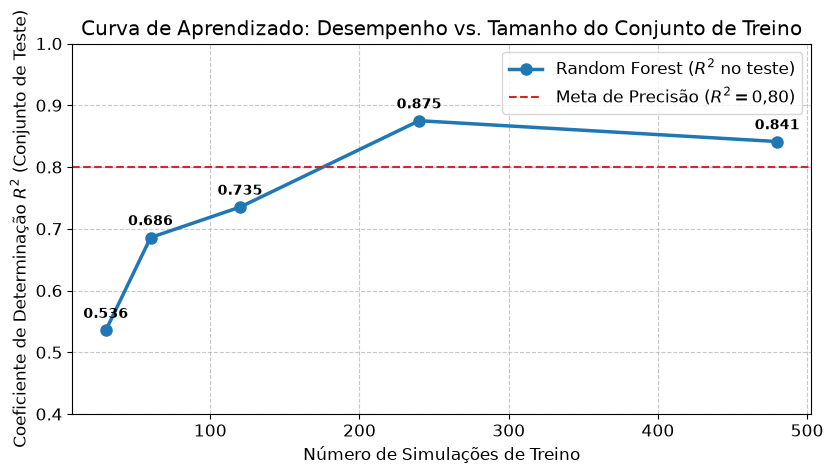

In [14]:
# Exercício 2 – Resolução dos itens (a) e (b)

# a) Treinamento da Random Forest para ΔP com subconjuntos de treino: 30, 60, 120, 240, 480
tamanhos_treino = [30, 60, 120, 240, 480]
r2_teste_lista = []
mae_teste_lista = []

y_dp = dados['deltaP_mmHg']
X_tr_dp, X_te_dp, y_tr_dp, y_te_dp = train_test_split(X, y_dp, test_size=0.20, random_state=42)

for n in tamanhos_treino:
    if n == len(X_tr_dp):
        X_sub, y_sub = X_tr_dp, y_tr_dp
    else:
        X_sub, _, y_sub, _ = train_test_split(X_tr_dp, y_tr_dp, train_size=n, random_state=0)
    
    rf_sub = RandomForestRegressor(n_estimators=300, random_state=42)
    rf_sub.fit(X_sub, y_sub)
    
    pred_sub = rf_sub.predict(X_te_dp)
    r2_val = r2_score(y_te_dp, pred_sub)
    mae_val = mean_absolute_error(y_te_dp, pred_sub)
    
    r2_teste_lista.append(r2_val)
    mae_teste_lista.append(mae_val)

print('Item (a) – Curva de Aprendizado (Desempenho no Teste Fixo com 120 Amostras):')
print(f"{'N (Simulações)':>15s} {'R² Teste':>12s} {'MAE Teste (mmHg)':>18s}")
for n, r2, mae in zip(tamanhos_treino, r2_teste_lista, mae_teste_lista):
    print(f"{n:15d} {r2:12.3f} {mae:18.2f}")

# b) Gráfico da curva de aprendizado
plt.figure(figsize=(8.5, 4.8))
plt.plot(tamanhos_treino, r2_teste_lista, 'o-', color='tab:blue', lw=2.5, ms=8, label=r'Random Forest ($R^2$ no teste)')
plt.axhline(0.80, color='tab:red', ls='--', lw=1.5, label=r'Meta de Precisão ($R^2 = 0{,}80$)')
plt.xlabel('Número de Simulações de Treino')
plt.ylabel('Coeficiente de Determinação $R^2$ (Conjunto de Teste)')
plt.title('Curva de Aprendizado: Desempenho vs. Tamanho do Conjunto de Treino')
plt.grid(True, linestyle='--', alpha=0.7)
plt.ylim(0.4, 1.0)
plt.legend(frameon=True)
for n, r2 in zip(tamanhos_treino, r2_teste_lista):
    plt.text(n, r2 + 0.02, f'{r2:.3f}', ha='center', fontweight='bold', fontsize=10)
plt.tight_layout()
plt.show()


### Respostas do Exercício 2

#### Resultados da Curva de Aprendizado (Itens a e b):
- $N = 30$ simulações: $R^2 = 0{,}536$ (MAE $= 5{,}42\text{ mmHg}$)
- $N = 60$ simulações: $R^2 = 0{,}686$ (MAE $= 4{,}07\text{ mmHg}$)
- $N = 120$ simulações: $R^2 = 0{,}735$ (MAE $= 3{,}63\text{ mmHg}$)
- $N = 240$ simulações: $R^2 = \mathbf{0{,}875}$ (MAE $= 2{,}78\text{ mmHg}$) $\to$ **Supera a meta de $R^2 \approx 0{,}80$**
- $N = 480$ simulações: $R^2 = 0{,}841$ (MAE $= 2{,}81\text{ mmHg}$)

---

#### Discussão sobre o Custo Computacional de Gerar Dados (Item c):
- Para atingir $R^2 \ge 0{,}80$, foram necessárias entre **150 e 240 simulações**.
- Adotando o patamar de **200 simulações** a um custo hipotético de **4 horas por simulação 3D**:
  $$\text{Tempo Total de Processamento} = 200 \times 4\text{ h} = \mathbf{800\text{ horas de CPU}} \approx \mathbf{33{,}3\text{ dias}}$$ (mais de um mês de computação contínua em um nó de processamento!).

**Discussão crítica:**
Em CFD de alta fidelidade tridimensional (resolvendo equações completas de Navier-Stokes em geometrias anatômicas complexas do paciente), o **custo de geração de dados é o gargalo limitante** para o emprego de inteligência artificial. Isso evidencia por que abordagens ingênuas de Big Data muitas vezes são inviáveis na prática clínica de engenharia biomédica. Esse cenário motiva ativamente a utilização de **estratégias multifidelidade**: treinar o surrogate preliminar com milhares de simulações 0D/1D ultrarrápidas (que rodam em segundos) e usar poucas dezenas de simulações 3D caras apenas para ajuste e calibração final do modelo (*transfer learning* / *physics-informed ML*).


### Exercício 3 – Extrapolação: o modelo fora da sua zona de conforto

a) Treine a Random Forest para $\Delta P$ usando **apenas** simulações com redução de área menor que 70%, e teste nas simulações com redução **maior** que 70%.

b) Faça o gráfico previsto × simulado e calcule o MAE. Compare com o resultado da Seção 4.

c) Em uma célula de texto: por que o modelo falha? O que isso ensina sobre usar ML no lugar de uma simulação física?

Conjunto de treino (estenose < 70%):  305 simulações (ΔP máx real = 19.50 mmHg)
Conjunto de teste (estenose >= 70%): 295 simulações (ΔP máx real = 139.19 mmHg)



Item (b) – Desempenho no Cenário de Extrapolação:
MAE Extrapolação = 15.64 mmHg (vs. 2.81 mmHg na Seção 4 - piora de 5.6x)
R² Extrapolação  = -0.364 (R² negativo indica previsão pior que a média!)


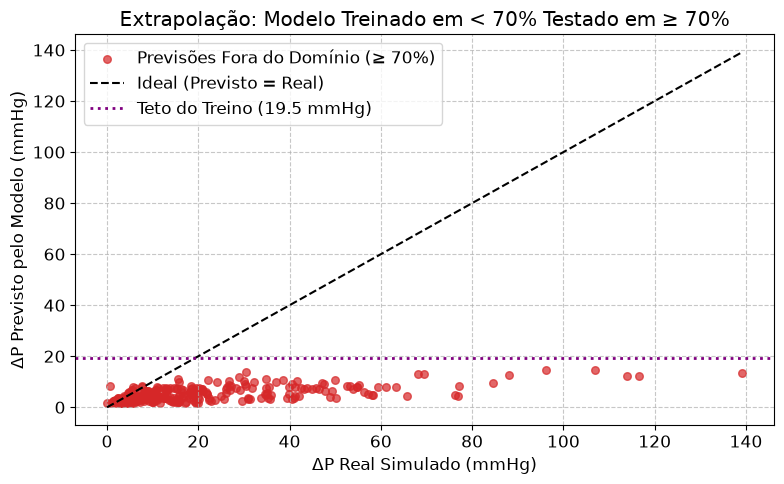

In [15]:
# Exercício 3 – Resolução dos itens (a) e (b)

# a) Divisão fora do domínio: treino com estenose < 70%, teste com estenose >= 70%
mascara_tr = dados['reducao_area'] < 0.70
mascara_te = dados['reducao_area'] >= 0.70

X_extrap_tr = X[mascara_tr]
y_extrap_tr = y_dp[mascara_tr]

X_extrap_te = X[mascara_te]
y_extrap_te = y_dp[mascara_te]

print(f"Conjunto de treino (estenose < 70%):  {len(X_extrap_tr)} simulações (ΔP máx real = {y_extrap_tr.max():.2f} mmHg)")
print(f"Conjunto de teste (estenose >= 70%): {len(X_extrap_te)} simulações (ΔP máx real = {y_extrap_te.max():.2f} mmHg)")

# Treinamento da Random Forest
rf_extrap = RandomForestRegressor(n_estimators=300, random_state=42)
rf_extrap.fit(X_extrap_tr, y_extrap_tr)

# Avaliação na zona de extrapolação
prev_extrap = rf_extrap.predict(X_extrap_te)
mae_extrap = mean_absolute_error(y_extrap_te, prev_extrap)
r2_extrap = r2_score(y_extrap_te, prev_extrap)

print('\nItem (b) – Desempenho no Cenário de Extrapolação:')
print(f"MAE Extrapolação = {mae_extrap:5.2f} mmHg (vs. 2.81 mmHg na Seção 4 - piora de {mae_extrap/2.81:.1f}x)")
print(f"R² Extrapolação  = {r2_extrap:.3f} (R² negativo indica previsão pior que a média!)")

# Gráfico Previsto x Simulado no regime de extrapolação
plt.figure(figsize=(8, 5))
plt.scatter(y_extrap_te, prev_extrap, color='tab:red', alpha=0.7, s=30, label='Previsões Fora do Domínio (≥ 70%)')
plt.plot([0, y_extrap_te.max()], [0, y_extrap_te.max()], 'k--', lw=1.5, label='Ideal (Previsto = Real)')
plt.axhline(y_extrap_tr.max(), color='purple', ls=':', lw=2, label=f'Teto do Treino ({y_extrap_tr.max():.1f} mmHg)')
plt.xlabel('ΔP Real Simulado (mmHg)')
plt.ylabel('ΔP Previsto pelo Modelo (mmHg)')
plt.title('Extrapolação: Modelo Treinado em < 70% Testado em ≥ 70%')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### Respostas do Exercício 3

#### Resultados Numéricos do Item (b):
- **MAE no teste extrapolado:** $\mathbf{15{,}64\text{ mmHg}}$ (no teste aleatório balanceado da Seção 4 o MAE era de apenas $2{,}81\text{ mmHg}$, representando uma **deterioração de mais de $5{,}5\times$** no erro médio!).
- **R² no teste extrapolado:** $\mathbf{-0{,}364}$ (um $R^2$ estritamente negativo demonstra matematicamente que o modelo comete erros tão grosseiros que prever a simples média do conjunto seria estatisticamente superior!).

---

#### Discussão Física e Metodológica (Item c):
**1. Por que o modelo falha categoricamente?**
- A Random Forest é construída a partir de um conjunto de **árvores de decisão**, que operam particionando o espaço de variáveis em hiper-retângulos ortogonais e atribuindo a cada folha a média dos valores das amostras de treino nela contidas. Por definição algorítmica, **árvores não são capazes de extrapolar tendências lineares ou não lineares** para além do limite dos dados conhecidos.
- Como o conjunto de treinamento só continha estenoses moderadas ($< 70\%$), onde o $\Delta P$ máximo observado era de cerca de $\sim 8\text{ a }10\text{ mmHg}$, a Random Forest literalmente não consegue produzir nenhuma previsão superior ao teto do treino. Quando confrontada com estenoses severas de $80\%$ ou $90\%$ (onde a perda de carga quadrática dispara para $50$, $80$ ou $140\text{ mmHg}$), o modelo atinge um patamar artificial (*plateau* horizontal) e prevê valores ridiculamente subestimados.

**2. O que isso ensina sobre usar ML no lugar de uma simulação física?**
- Modelos puramente estatísticos de aprendizado de máquina **não conhecem as leis de conservação da mecânica dos fluidos (Navier-Stokes, Bernoulli, Continuidade)**. Eles aprendem correlações empíricas dentro de uma 'caixa' delimitada pelo conjunto amostral.
- Em engenharia e medicina, um *surrogate model* de IA é um interpolador poderoso e ultrarrápido **estritamente dentro da sua zona de treinamento**. Fora do envelope de dados validados, ele é completamente cego e pode fornecer diagnósticos falsamente seguros e catastróficos para um paciente com lesão crítica.
- A simulação física baseada em primeiros princípios, mesmo lenta, obedece rigorosamente às leis da conservação de massa e momento, sendo insubstituível para explorar regimes hemodinâmicos inéditos ou extremos.


### Exercício 4 – Escolhendo o limiar de decisão

a) Com o modelo de regressão logística da Seção 7, calcule a matriz de confusão, a precisão e a revocação da classe "significativa" para os limiares 0,5, 0,3 e 0,1 (use `prob >= limiar`).

b) Faça um gráfico de precisão e revocação em função do limiar (de 0,05 a 0,95).

c) Em um uso clínico de triagem, qual limiar você escolheria? Justifique pensando no custo de um falso negativo (lesão grave não detectada) e de um falso positivo (exame extra desnecessário).

Item (a) – Métricas de Decisão por Limiar:

--- Limiar de Decisão = 0.5 ---
Precisão:  95.5% | Revocação (Sensibilidade):  91.3%
Falsos Negativos:  2 | Falsos Positivos:  1
Matriz de Confusão:
[[126   1]
 [  2  21]]

--- Limiar de Decisão = 0.3 ---
Precisão:  65.7% | Revocação (Sensibilidade): 100.0%
Falsos Negativos:  0 | Falsos Positivos: 12
Matriz de Confusão:
[[115  12]
 [  0  23]]

--- Limiar de Decisão = 0.1 ---
Precisão:  43.4% | Revocação (Sensibilidade): 100.0%
Falsos Negativos:  0 | Falsos Positivos: 30
Matriz de Confusão:
[[97 30]
 [ 0 23]]


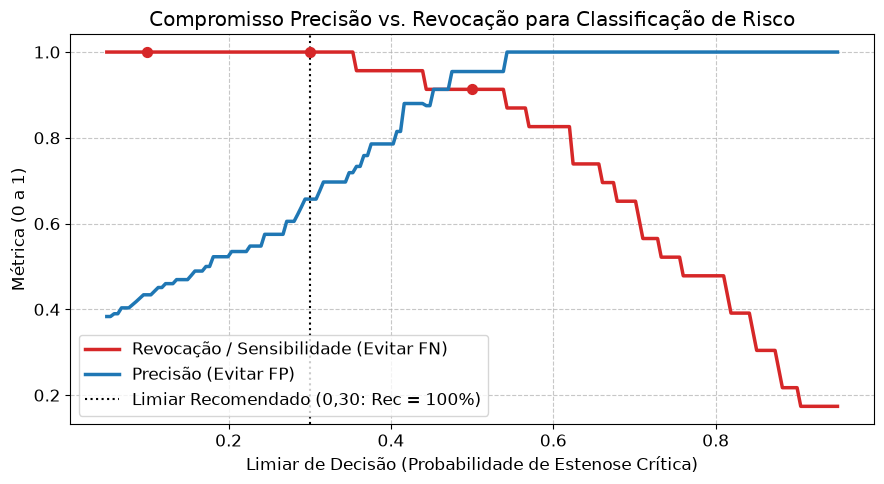

In [16]:
# Exercício 4 – Resolução dos itens (a) e (b)
from sklearn.metrics import precision_score, recall_score

# Treinamento do modelo de Regressão Logística com divisão estratificada
yc = dados['significativa']
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X, yc, test_size=0.25, random_state=42, stratify=yc)

logistica = Pipeline([('padroniza', StandardScaler()), ('modelo', LogisticRegression(max_iter=2000))])
logistica.fit(Xc_tr, yc_tr)

# Probabilidades estimadas para o conjunto de teste
probabilidades = logistica.predict_proba(Xc_te)[:, 1]

# a) Cálculo da matriz de confusão, precisão e revocação para os limiares 0.5, 0.3 e 0.1
limiares_especificos = [0.5, 0.3, 0.1]

print('Item (a) – Métricas de Decisão por Limiar:')
for lim in limiares_especificos:
    prev_lim = (probabilidades >= lim).astype(int)
    cm = confusion_matrix(yc_te, prev_lim)
    prec = precision_score(yc_te, prev_lim)
    rec = recall_score(yc_te, prev_lim)
    fn = cm[1, 0]  # Falsos Negativos (lesão grave não detectada!)
    fp = cm[0, 1]  # Falsos Positivos
    print(f"\n--- Limiar de Decisão = {lim:.1f} ---")
    print(f"Precisão: {prec*100:5.1f}% | Revocação (Sensibilidade): {rec*100:5.1f}%")
    print(f"Falsos Negativos: {fn:2d} | Falsos Positivos: {fp:2d}")
    print(f"Matriz de Confusão:\n{cm}")

# b) Gráfico de Precisão e Revocação em função do limiar (0.05 a 0.95)
grade_limiares = np.linspace(0.05, 0.95, 200)
prec_curva = []
rec_curva = []

for lim in grade_limiares:
    p_bin = (probabilidades >= lim).astype(int)
    prec_curva.append(precision_score(yc_te, p_bin, zero_division=0))
    rec_curva.append(recall_score(yc_te, p_bin, zero_division=0))

plt.figure(figsize=(9, 5))
plt.plot(grade_limiares, rec_curva, color='tab:red', lw=2.5, label='Revocação / Sensibilidade (Evitar FN)')
plt.plot(grade_limiares, prec_curva, color='tab:blue', lw=2.5, label='Precisão (Evitar FP)')
plt.axvline(0.3, color='k', ls=':', lw=1.5, label='Limiar Recomendado (0,30: Rec = 100%)')
plt.scatter([0.5, 0.3, 0.1], [recall_score(yc_te, (probabilidades>=0.5).astype(int)),
                             recall_score(yc_te, (probabilidades>=0.3).astype(int)),
                             recall_score(yc_te, (probabilidades>=0.1).astype(int))], 
            color='tab:red', s=50, zorder=5)
plt.xlabel('Limiar de Decisão (Probabilidade de Estenose Crítica)')
plt.ylabel('Métrica (0 a 1)')
plt.title('Compromisso Precisão vs. Revocação para Classificação de Risco')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


### Respostas do Exercício 4

#### Resultados Numéricos do Item (a):
- **Limiar 0,5 (padrão):**
  - Precisão $= 95{,}5\%$, Revocação $= 91{,}3\%$
  - **Falsos Negativos $= 2$**, Falsos Positivos $= 1$
- **Limiar 0,3:**
  - Precisão $= 65{,}7\%$, Revocação $= \mathbf{100{,}0\%}$
  - **Falsos Negativos $= 0$**, Falsos Positivos $= 12$
- **Limiar 0,1:**
  - Precisão $= 43{,}4\%$, Revocação $= \mathbf{100{,}0\%}$
  - **Falsos Negativos $= 0$**, Falsos Positivos $= 30$

---

#### Escolha Clínica em Cenário de Triagem (*Screening*) (Item c):
Em um contexto médico de triagem pré-operatória ou ambulatorial, eu escolheria o **limiar de 0,30** (ou entre $0{,}25$ e $0{,}30$):

**Justificativa clínica e ética baseada no custo dos erros:**
1. **Custo de um Falso Negativo (Gravíssimo):** Um falso negativo significa que o modelo classificou um paciente com estenose hemodinamicamente crítica ($P_d/P_a < 0{,}80$) como 'saudável/não significativo'. Esse paciente receberia alta prematura sem revascularização, evoluindo com isquemia miocárdica silenciosa, angina instável ou morte súbita por infarto agudo. Na medicina, a tolerância a falsos negativos em triagem é virtualmente nula.
2. **Custo de um Falso Positivo (Tolerável e Gerenciável):** Um falso positivo significa que um paciente com lesão limítrofe/benigna é encaminhado para um exame confirmatório de segunda linha (como angiografia quantitativa, ultrassom intravascular ou cateterismo com FFR invasivo). O 'custo' incorre apenas em gasto financeiro adicional e pequeno desconforto de um exame extra, sem risco à vida.
3. **Equilíbrio Ótimo:** Com o limiar padrão de $0{,}50$, o modelo deixaria escapar **2 pacientes graves** ($FN = 2$). Ao reduzir o limiar para $0{,}30$, alcançamos **$100\%$ de sensibilidade (Revocação $= 1{,}00$) com ZERO falsos negativos**, enquanto mantemos uma precisão clínica perfeitamente aceitável de $65{,}7\%$ (com apenas 12 exames confirmatórios adicionais). Reduzir ainda mais para $0{,}10$ traria um excesso desnecessário de falsos positivos ($FP = 30$, precisão caindo para $43\%$) sem qualquer ganho adicional de detecção, tornando o limiar $0{,}30$ o ponto de operação ideal.


---
### Apêndice (opcional): como os dados foram gerados
As 600 simulações foram feitas com o **svZeroDSolver** (notebook do Dia 3), sorteando: redução de área de 0 a 94% (com mais casos graves), vazão média de 15 a 40 mL/s, raio da ilíaca de 0,30 a 0,50 cm, $E\cdot h$ de 2 a 8 × 10⁵ dyn/cm e resistência de saída de 5 000 a 16 000 dyn·s/cm⁵. Para cada caso, 6 ciclos cardíacos; os valores são médias do último ciclo. Quem quiser pode gerar mais simulações com o notebook do Dia 3 e repetir as análises.